In [1]:
from pathlib import Path
import random
import cv2
import matplotlib.pyplot as plt

# Find data/ from the current directory or one of its parent directories.
DATA_DIR = next(
    (folder / "data" for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / "data").is_dir()),
    None,
)
if DATA_DIR is None:
    raise FileNotFoundError("Could not find a data/ folder in the current directory or its parents.")

SAMPLE_SIZE = 30
RANDOM_SEED = 42

extensions = {".jpg", ".jpeg", ".png", ".bmp"}

all_paths = sorted([
    p for p in DATA_DIR.rglob("*")
    if p.suffix.lower() in extensions
])

random.seed(RANDOM_SEED)
signer_dirs = sorted(
    (folder for folder in DATA_DIR.iterdir() if folder.is_dir()),
    key=lambda folder: folder.name.casefold(),
)
if not signer_dirs:
    raise FileNotFoundError(f"No signer folders found under {DATA_DIR}.")

# Keep SAMPLE_SIZE as the total sample size, distributed evenly across signers.
images_per_signer = max(1, SAMPLE_SIZE // len(signer_dirs))
sample_paths = []
sample_counts = {}
for signer_dir in signer_dirs:
    signer_images = sorted(
        path for path in signer_dir.rglob("*")
        if path.suffix.lower() in extensions
    )
    signer_sample = random.sample(
        signer_images, min(images_per_signer, len(signer_images))
    )
    sample_paths.extend(signer_sample)
    sample_counts[signer_dir.name] = len(signer_sample)

print("Total images:", len(all_paths))
print("Selected images:", len(sample_paths))
print("Selected per signer:", sample_counts)

def read_image(path):
    return cv2.imread(str(path))



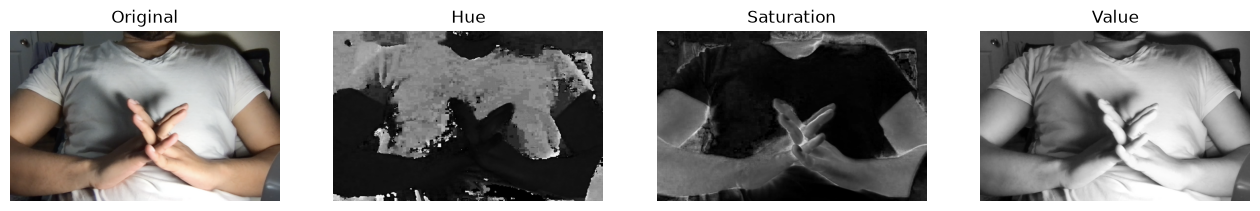

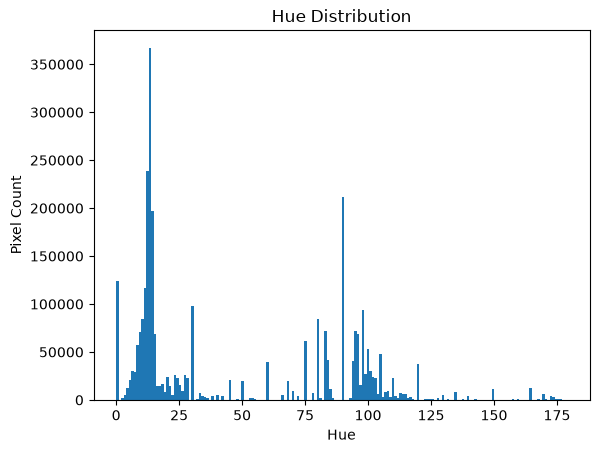

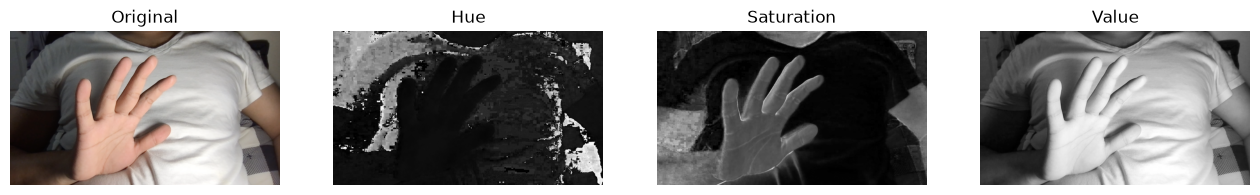

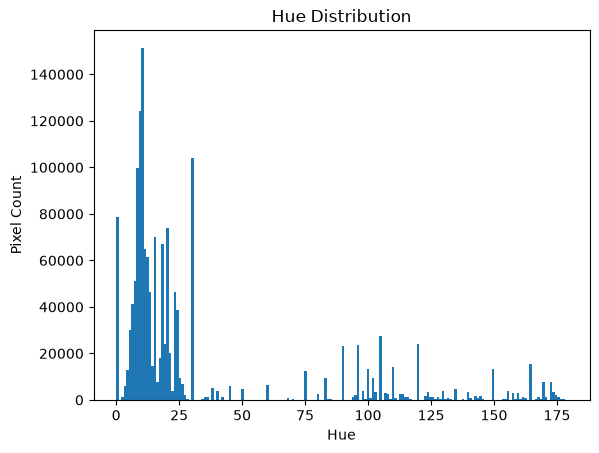

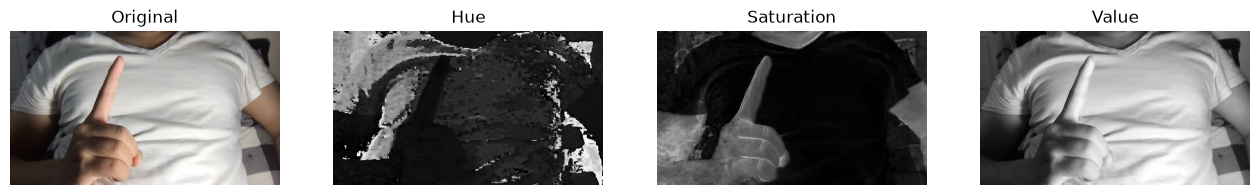

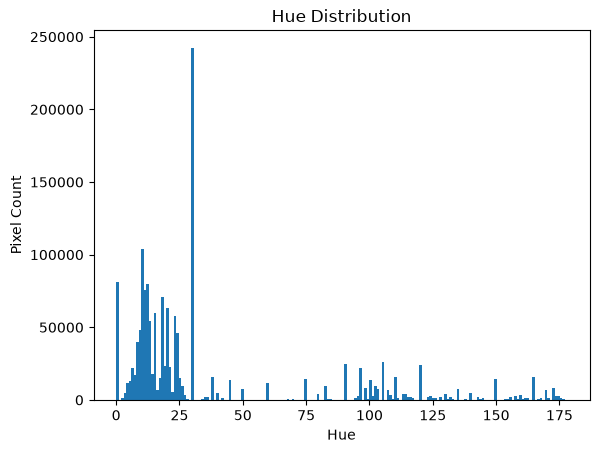

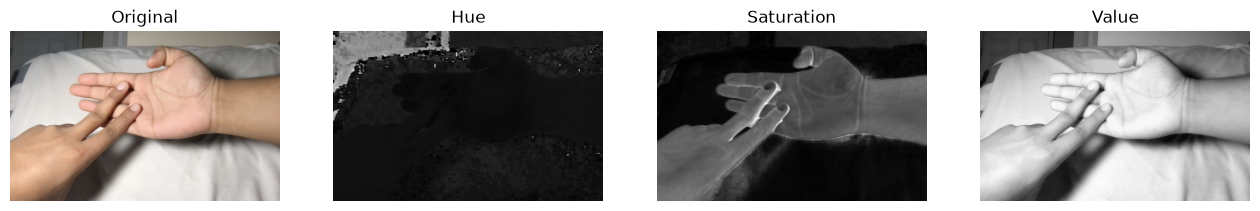

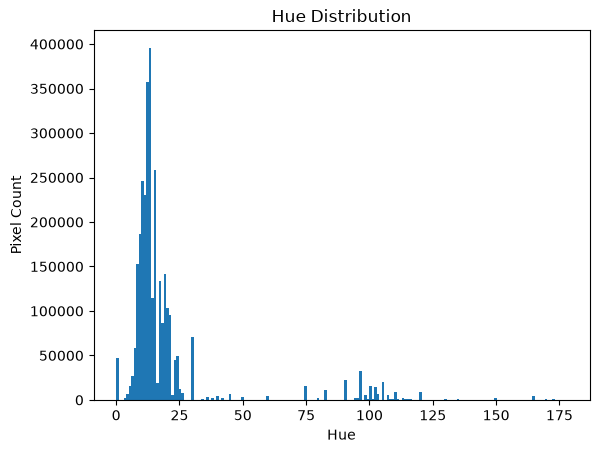

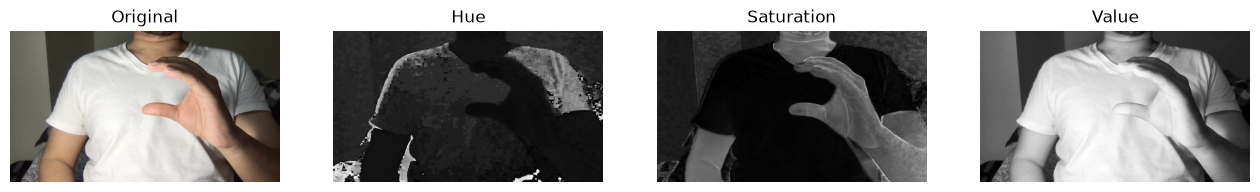

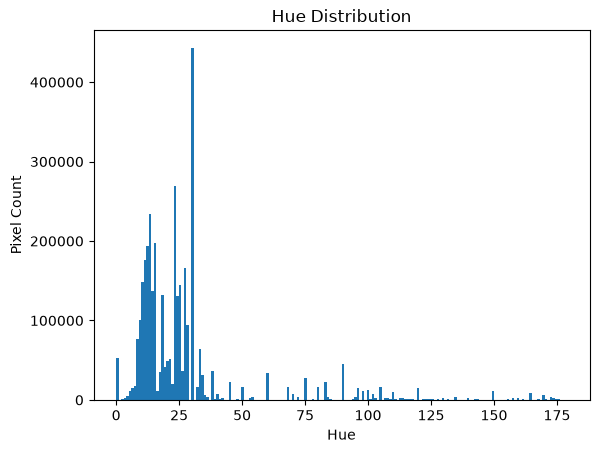

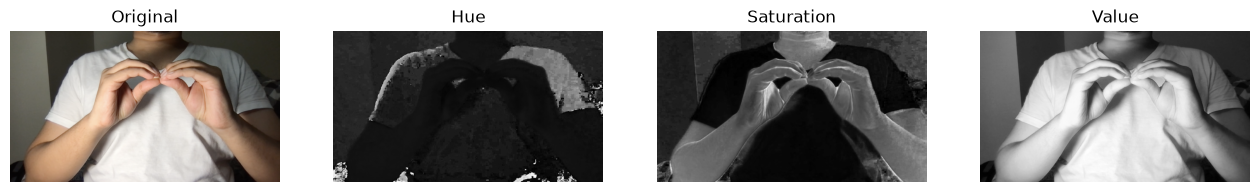

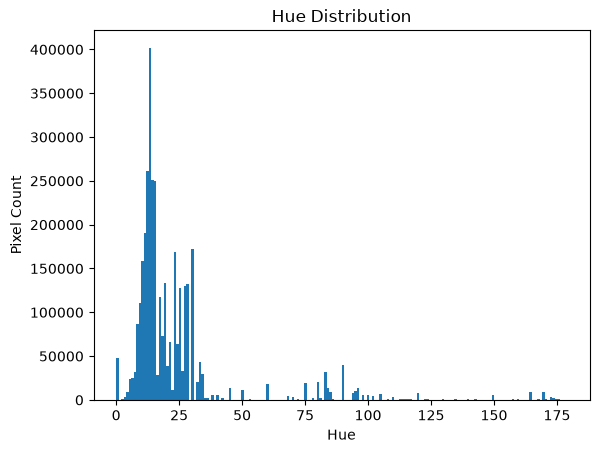

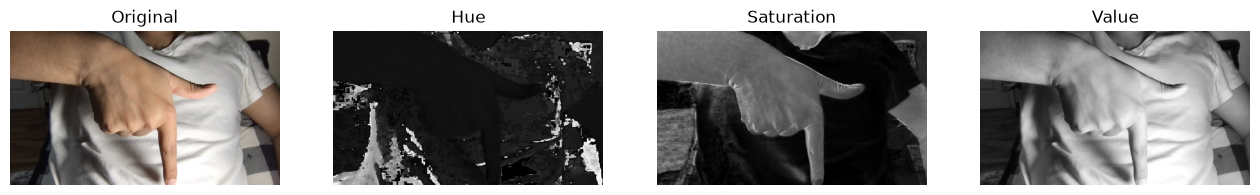

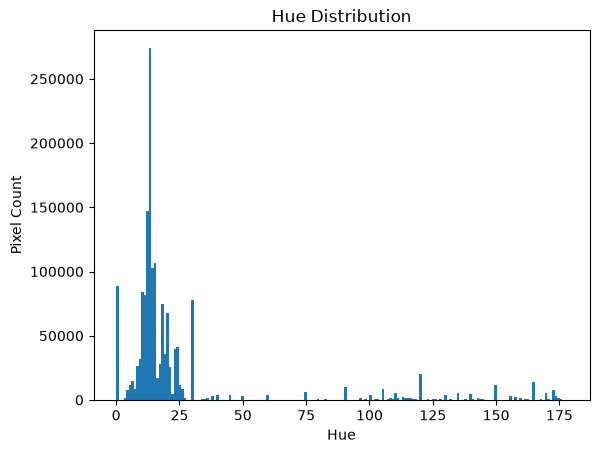

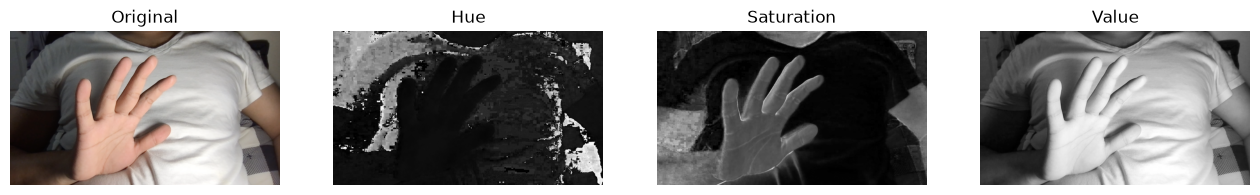

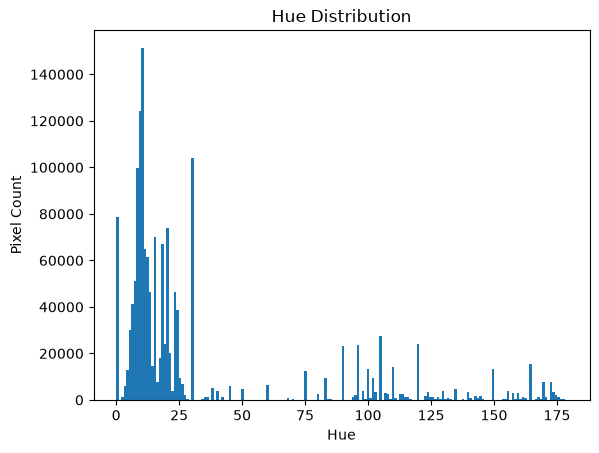

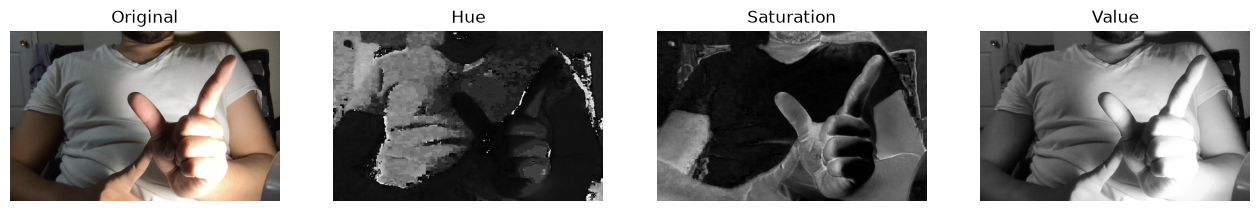

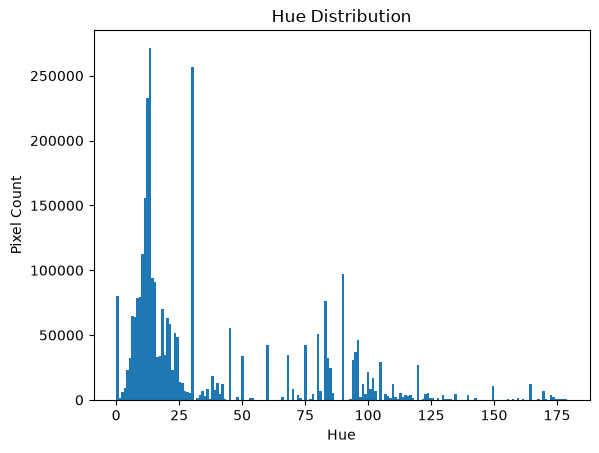

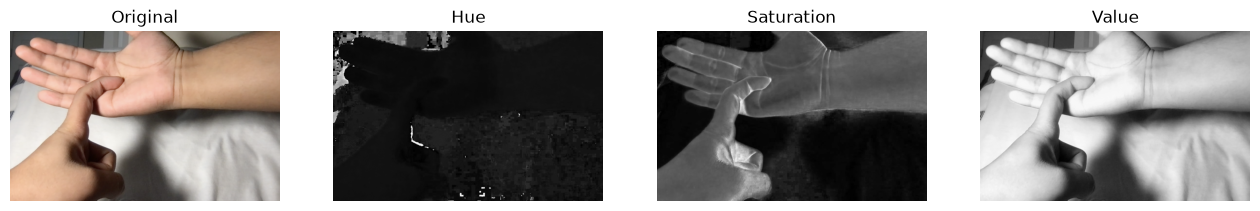

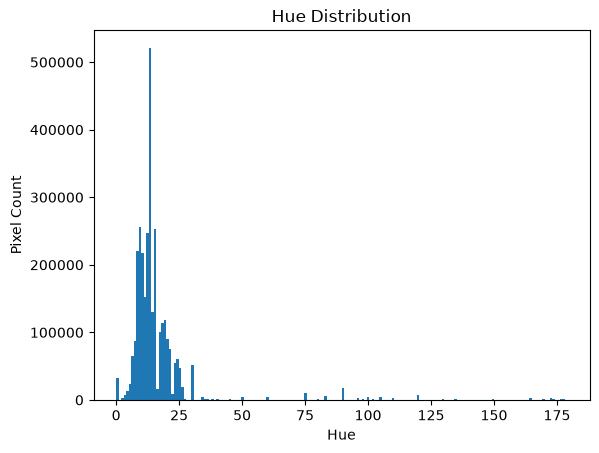

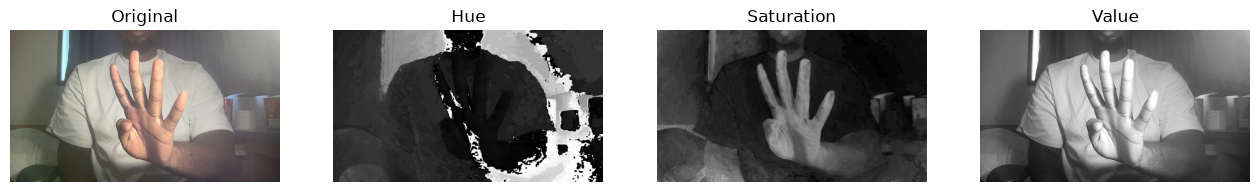

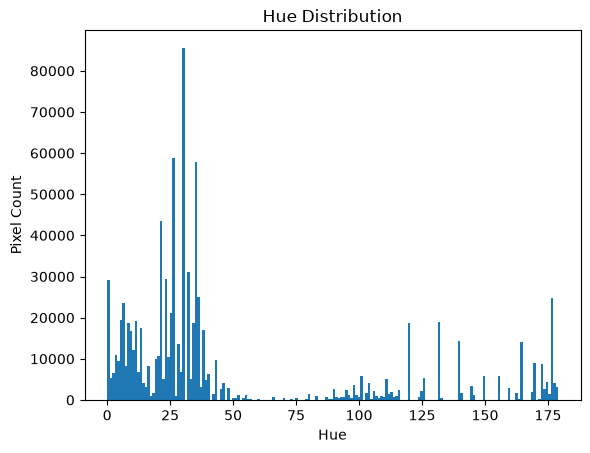

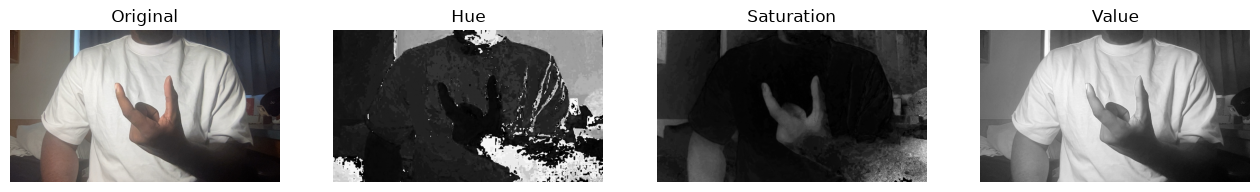

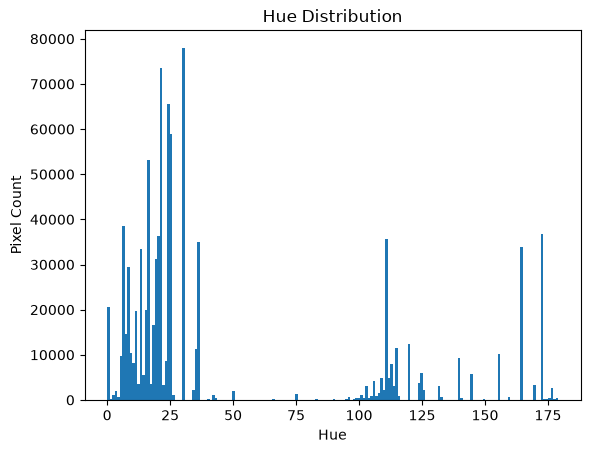

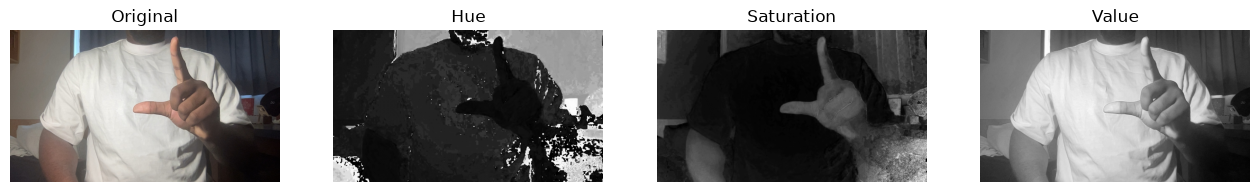

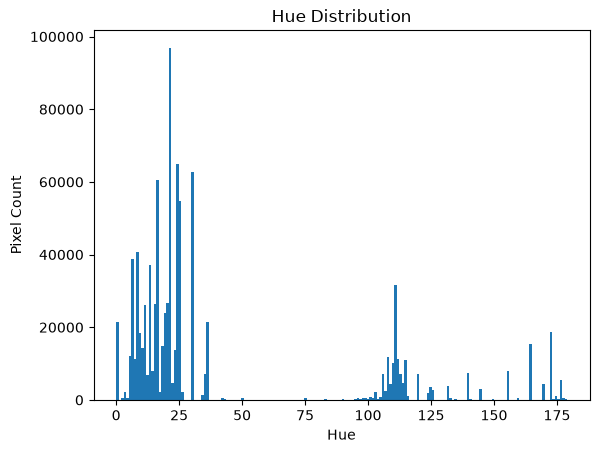

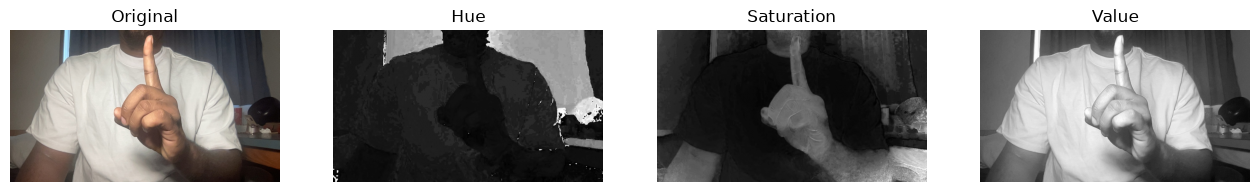

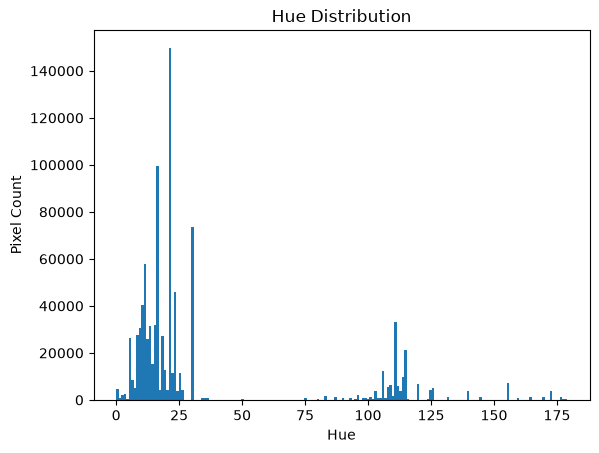

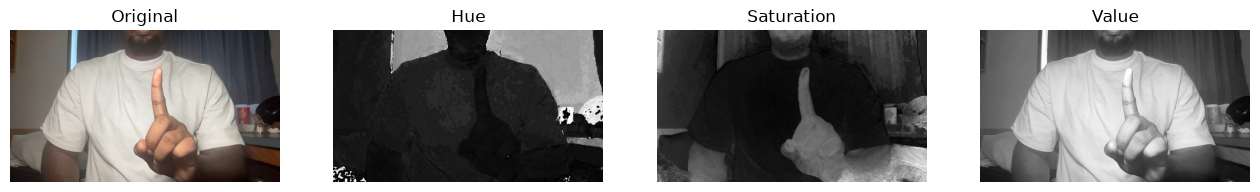

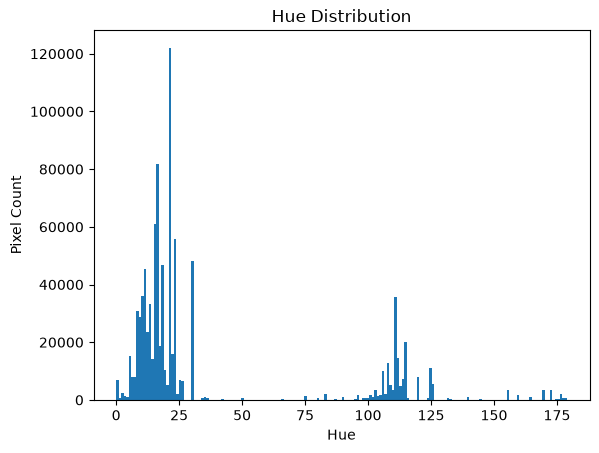

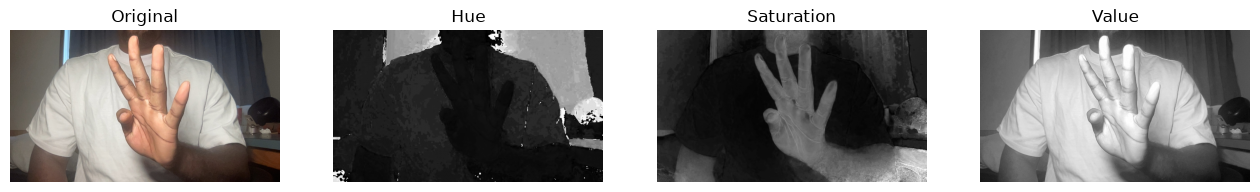

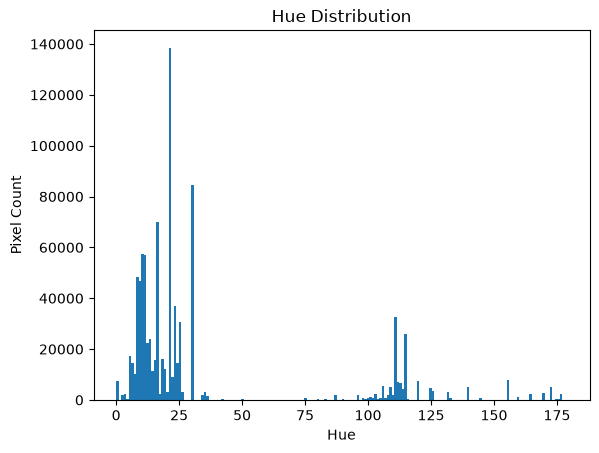

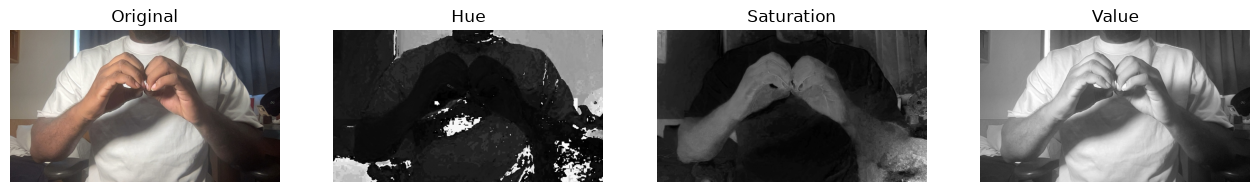

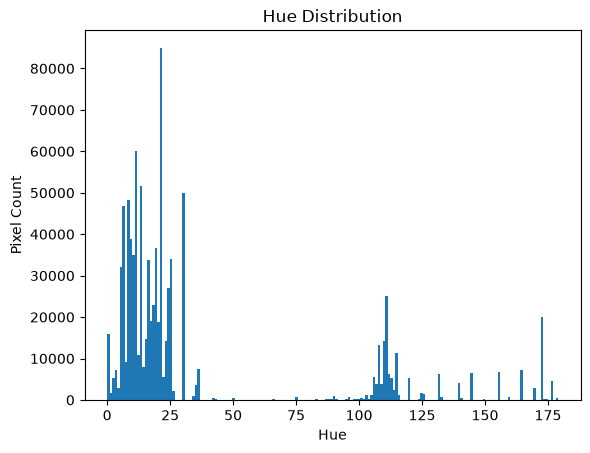

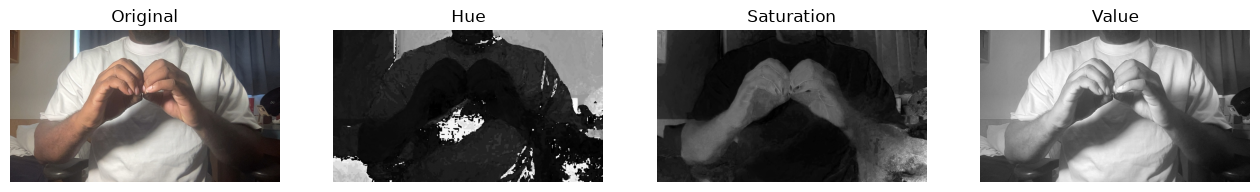

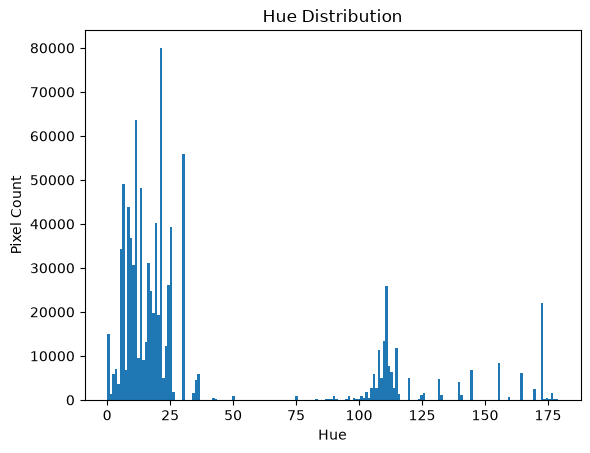

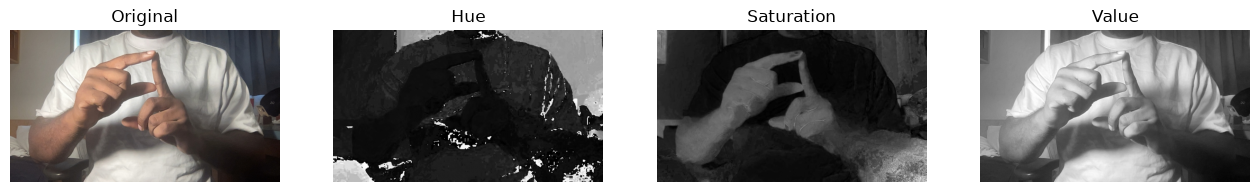

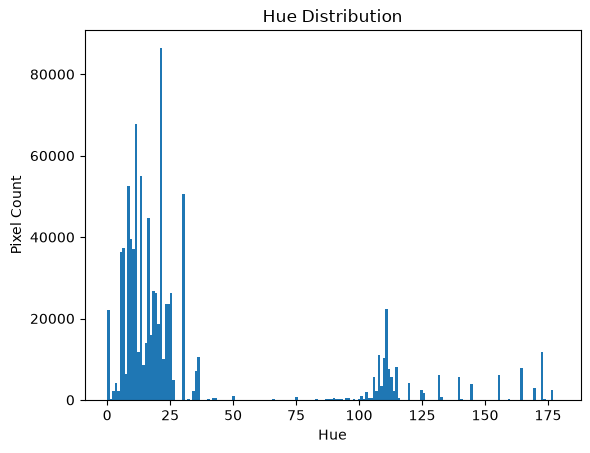

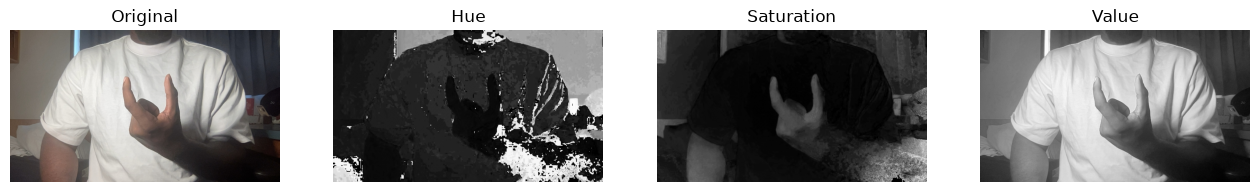

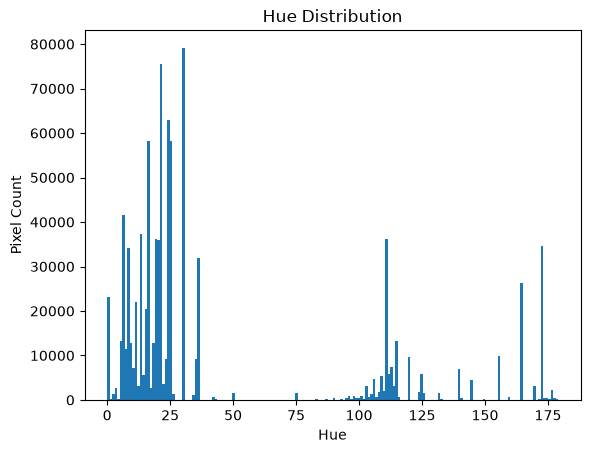

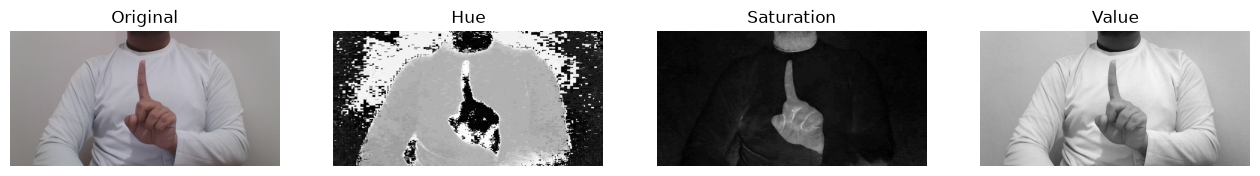

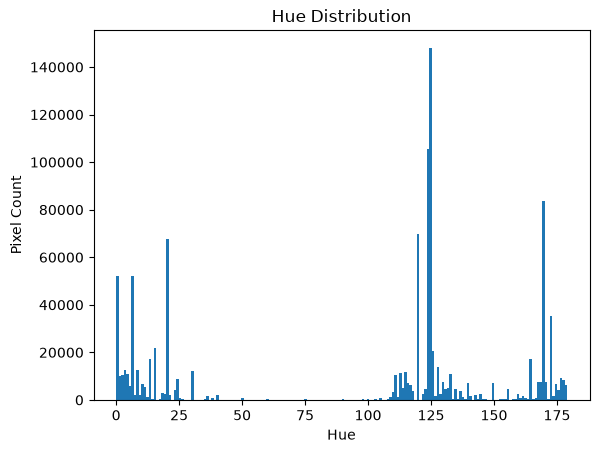

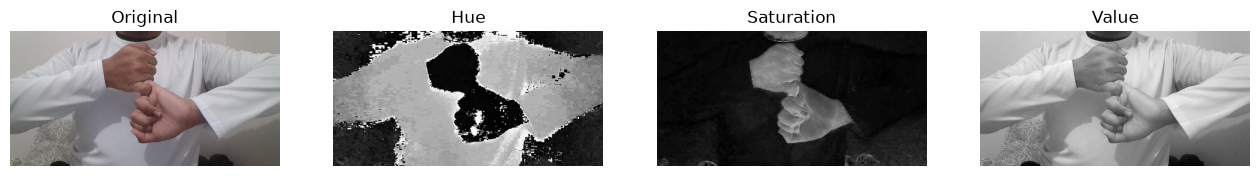

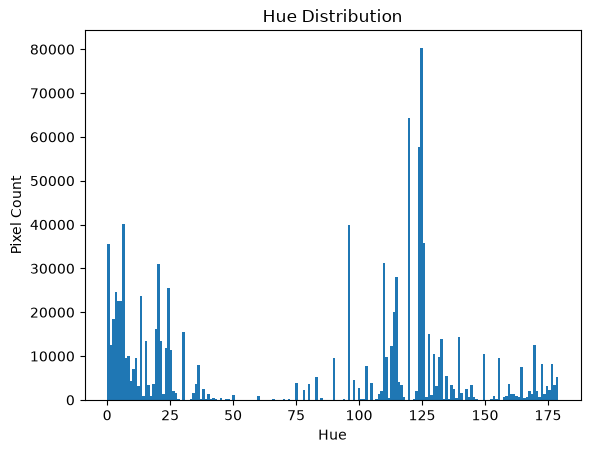

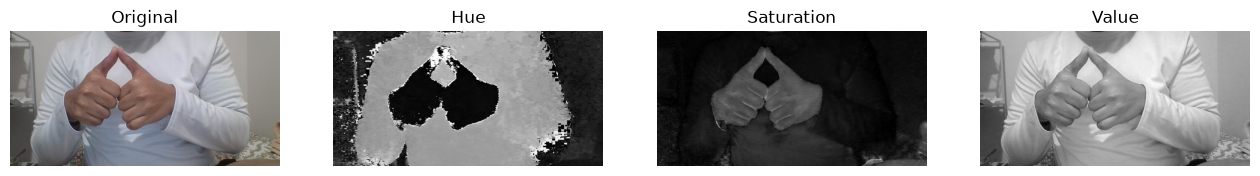

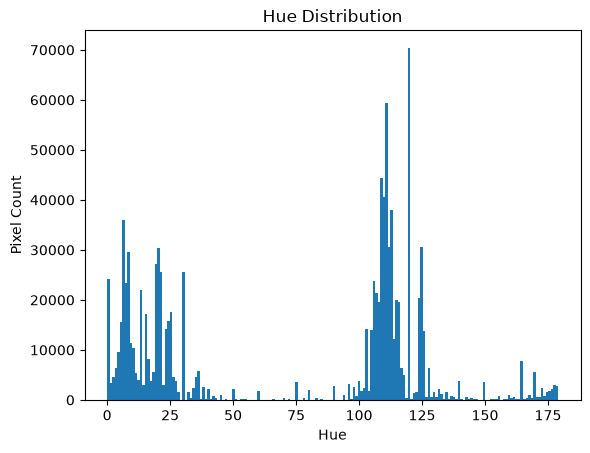

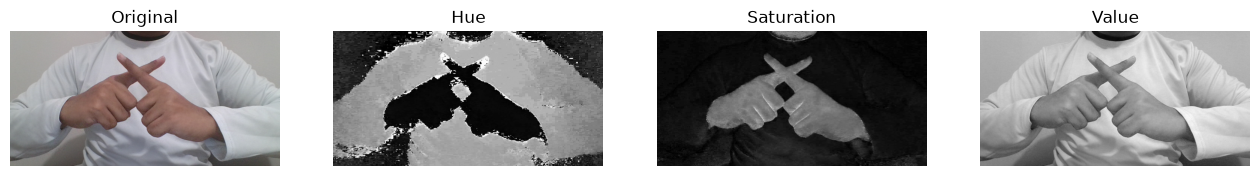

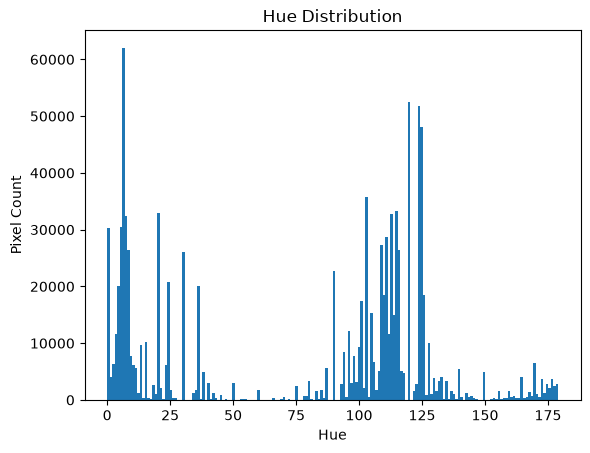

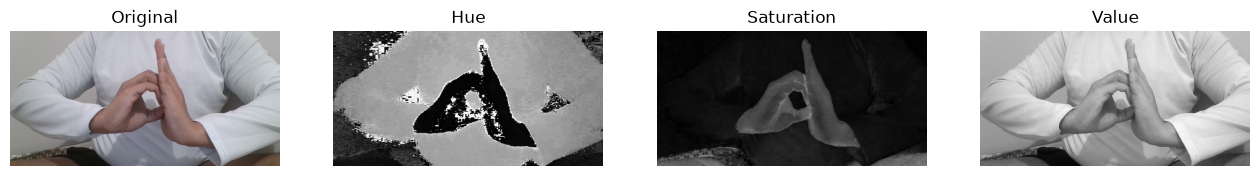

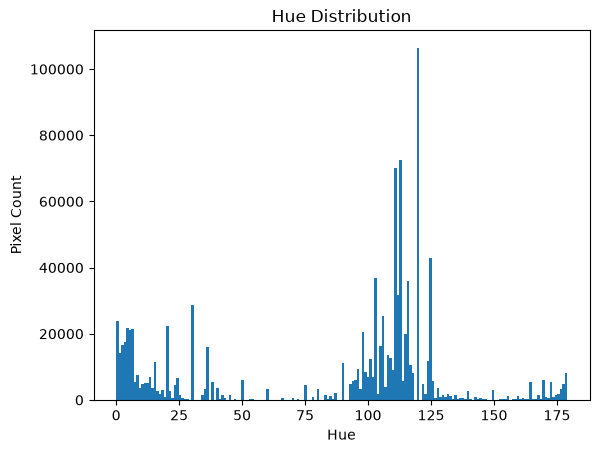

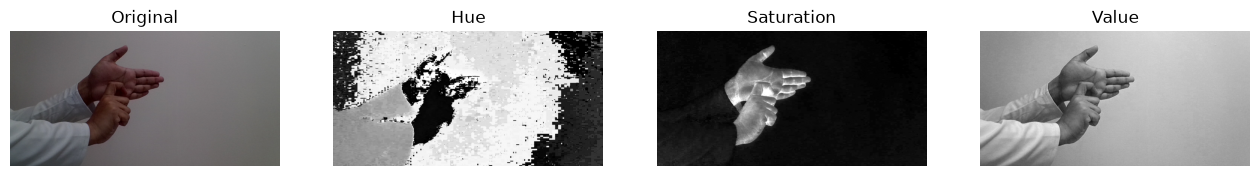

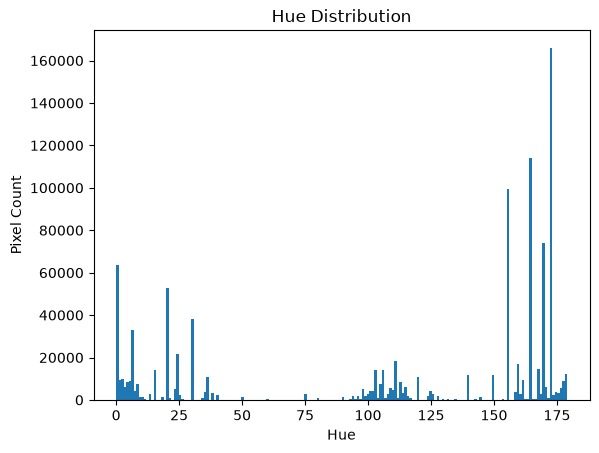

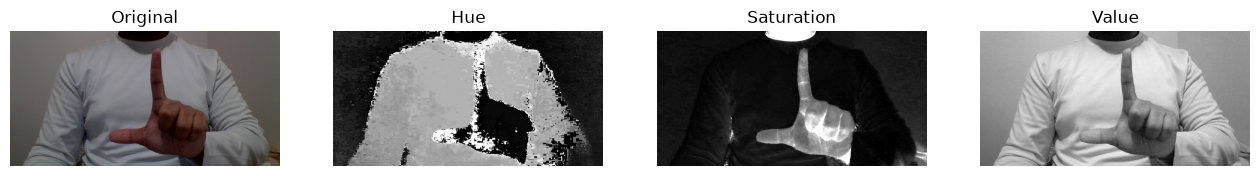

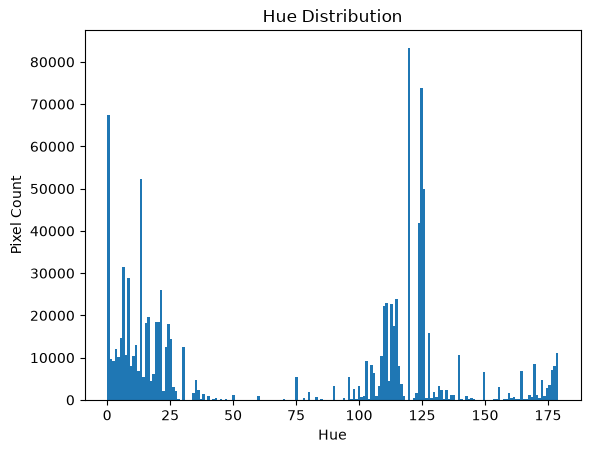

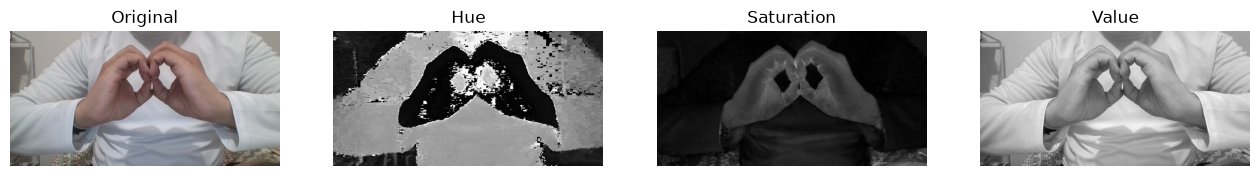

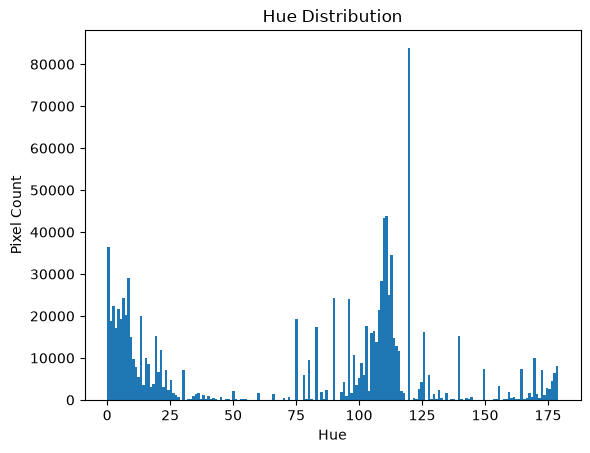

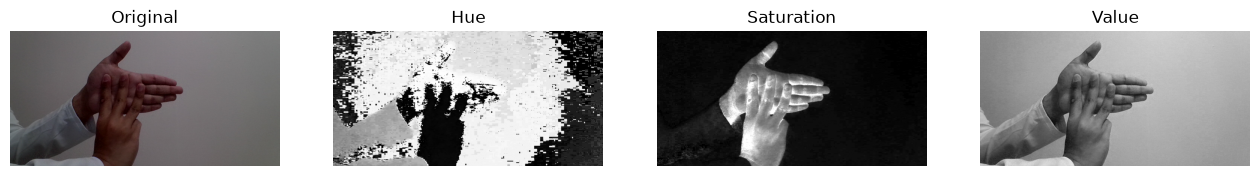

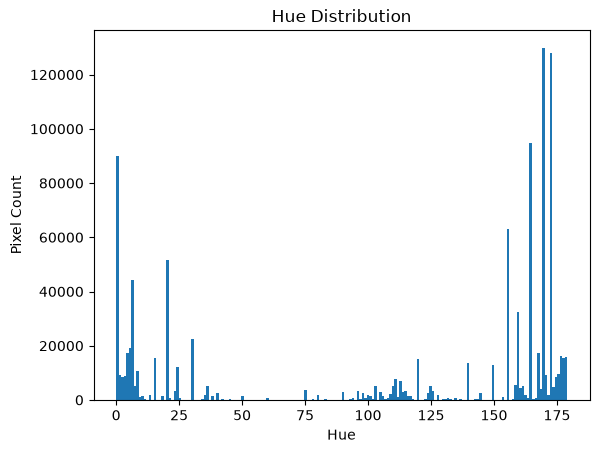

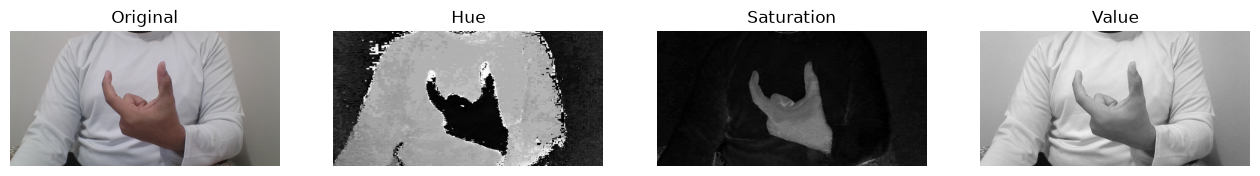

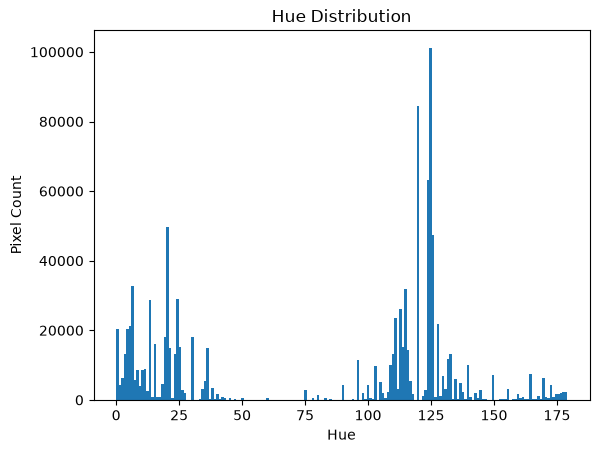

In [3]:
for path in sample_paths:

    image = read_image(path)

    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

    H, S, V = cv2.split(hsv)

    fig, ax = plt.subplots(1, 4, figsize=(16, 4))

    images = [
        cv2.cvtColor(image, cv2.COLOR_BGR2RGB),
        H, S, V
    ]

    titles = ["Original", "Hue", "Saturation", "Value"]

    for a, img, title in zip(ax, images, titles):
        a.imshow(img, cmap="gray" if img.ndim == 2 else None)
        a.set_title(title)
        a.axis("off")

    plt.show()

    plt.hist(H.ravel(), bins=180)
    plt.title("Hue Distribution")
    plt.xlabel("Hue")
    plt.ylabel("Pixel Count")
    plt.show()